# Eksplorasi Data Transaksi Kedai Kopi (3 Outlet)

Notebook ini melakukan **Exploratory Data Analysis (EDA)** terhadap data transaksi penjualan dari 3 outlet kedai kopi periode **Januari - September 2025**.

Dataset: `Transactions.csv` (53.820 baris transaksi)

Kolom yang tersedia:
- `Outlet` — kode outlet (SHOP001, SHOP002, SHOP003)
- `Date`, `Time` — tanggal dan waktu transaksi
- `NetSales`, `Tax`, `TotalAmount` — nilai penjualan bersih, pajak, dan total dibayar
- `ReceiptNumber` — nomor struk
- `Items` — daftar item yang dibeli (dipisah koma jika lebih dari satu)
- `TotalItem` — jumlah item dalam transaksi
- `PaymentMethod` — metode pembayaran (BCA, Cash, GoFood)
- `UseLoyaltyCard` — apakah transaksi menggunakan kartu loyalitas (0/1)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3


In [2]:
df = pd.read_csv('data/Transactions.csv')
df.head()

,Outlet,Date,Time,NetSales,Tax,TotalAmount,ReceiptNumber,Items,TotalItem,PaymentMethod,UseLoyaltyCard
0,SHOP001,2025-01-02,07:01:05,20720.721,2279.279,23000,SHOP001JAN2500001,Basic Latte (Ice Arabica),1,BCA,0
1,SHOP001,2025-01-02,07:04:11,18018.018,1981.982,20000,SHOP001JAN2500002,BLACK (Houseblend),1,BCA,0
2,SHOP002,2025-01-02,07:10:46,39639.640,4360.360,44000,SHOP002JAN2500001,"Friendly Coffee (Hot), Shakencano",2,Cash,0
3,SHOP002,2025-01-02,07:14:25,36036.036,3963.964,40000,SHOP002JAN2500002,"BLACK (Arabica), Americano (Hot Arabica)",2,Cash,0
4,SHOP002,2025-01-02,07:23:05,36036.036,3963.964,40000,SHOP002JAN2500003,"WHITE (Arabica), Susu Oat",2,Cash,0


## 1. Gambaran Umum Data

In [3]:
print(f"Jumlah baris 	: {df.shape[0]:,}")
print(f"Jumlah kolom	: {df.shape[1]}")
df.info()


Jumlah baris 	: 53,820
Jumlah kolom	: 11
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53820 entries, 0 to 53819
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Outlet          53820 non-null  object 
 1   Date            53820 non-null  object 
 2   Time            53820 non-null  object 
 3   NetSales        53820 non-null  float64
 4   Tax             53820 non-null  float64
 5   TotalAmount     53820 non-null  int64  
 6   ReceiptNumber   53820 non-null  object 
 7   Items           53820 non-null  object 
 8   TotalItem       53820 non-null  int64  
 9   PaymentMethod   53820 non-null  object 
 10  UseLoyaltyCard  53820 non-null  int64  
dtypes: float64(2), int64(3), object(6)
memory usage: 4.5+ MB


In [4]:
df.isna().sum().to_frame('missing_values')


,missing_values
Outlet,0
Date,0
Time,0
NetSales,0
Tax,0
TotalAmount,0
ReceiptNumber,0
Items,0
TotalItem,0
PaymentMethod,0


In [5]:
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Outlet,53820,3,SHOP001,26250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,53820,272,2025-06-15,282,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,53820,34813,19:50:39,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NetSales,53820.0,NaN,NaN,NaN,22016.598672,10172.06261,0.0,18018.018,20720.721,27027.027,54054.054
Tax,53820.0,NaN,NaN,NaN,2421.825705,1118.926902,0.0,1981.982,2279.279,2972.973,5945.946
TotalAmount,53820.0,NaN,NaN,NaN,24438.424378,11290.989512,0.0,20000.0,23000.0,30000.0,60000.0
ReceiptNumber,53820,53820,SHOP001JAN2500001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Items,53820,5370,Jus Semangka,544,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TotalItem,53820.0,NaN,NaN,NaN,1.151486,0.358526,1.0,1.0,1.0,1.0,2.0
PaymentMethod,53820,3,BCA,42805,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
print("Jumlah ReceiptNumber duplikat:", df['ReceiptNumber'].duplicated().sum())


Jumlah ReceiptNumber duplikat: 0


## 2. Pembersihan Data & Feature Engineering

- Menggabungkan `Date` + `Time` menjadi satu kolom datetime.
- Mengekstrak fitur waktu tambahan: bulan, nama hari, jam, dan penanda akhir pekan.


In [7]:
df['Date'] = pd.to_datetime(df['Date'])
df['DateTime'] = pd.to_datetime(df['Date'].astype(str) + ' ' + df['Time'])

df['Month'] = df['Date'].dt.month
df['MonthName'] = df['Date'].dt.strftime('%b')
df['DayOfWeek'] = df['Date'].dt.day_name()
df['Hour'] = pd.to_datetime(df['Time'], format='%H:%M:%S').dt.hour
df['IsWeekend'] = df['Date'].dt.dayofweek >= 5

df[['Date','Time','DateTime','Month','MonthName','DayOfWeek','Hour','IsWeekend']].head()


,Date,Time,DateTime,Month,MonthName,DayOfWeek,Hour,IsWeekend
0,2025-01-02,07:01:05,2025-01-02 07:01:05,1,Jan,Thursday,7,False
1,2025-01-02,07:04:11,2025-01-02 07:04:11,1,Jan,Thursday,7,False
2,2025-01-02,07:10:46,2025-01-02 07:10:46,1,Jan,Thursday,7,False
3,2025-01-02,07:14:25,2025-01-02 07:14:25,1,Jan,Thursday,7,False
4,2025-01-02,07:23:05,2025-01-02 07:23:05,1,Jan,Thursday,7,False


In [8]:
print("Rentang tanggal:", df['Date'].min().date(), "s/d", df['Date'].max().date())
print("Jumlah hari unik dengan transaksi:", df['Date'].nunique())


Rentang tanggal: 2025-01-02 s/d 2025-09-30
Jumlah hari unik dengan transaksi: 272


## 3. Ringkasan Penjualan

Catatan: terdapat transaksi dengan `TotalAmount = 0`. Ini kemungkinan besar adalah transaksi **penukaran (redeem) item gratis** menggunakan kartu loyalitas — akan dicek lebih lanjut di bagian Loyalty Card.


In [9]:
total_revenue = df['TotalAmount'].sum()
total_transactions = len(df)
avg_transaction = df.loc[df['TotalAmount'] > 0, 'TotalAmount'].mean()

print(f"Total pendapatan (TotalAmount)	: Rp {total_revenue:,.0f}")
print(f"Total transaksi			: {total_transactions:,}")
print(f"Rata-rata nilai transaksi (>0)	: Rp {avg_transaction:,.0f}")
print(f"Transaksi dengan nilai Rp 0	: {(df['TotalAmount']==0).sum():,} ({(df['TotalAmount']==0).mean()*100:.1f}%)")


Total pendapatan (TotalAmount)	: Rp 1,315,276,000
Total transaksi			: 53,820
Rata-rata nilai transaksi (>0)	: Rp 25,252
Transaksi dengan nilai Rp 0	: 1,733 (3.2%)


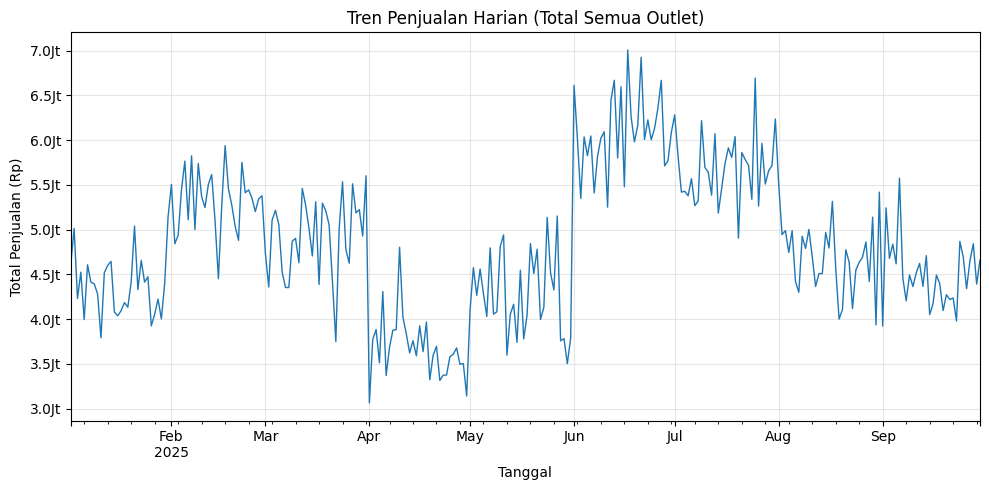

In [10]:
daily_sales = df.groupby('Date')['TotalAmount'].sum()

fig, ax = plt.subplots()
daily_sales.plot(ax=ax, linewidth=1)
ax.set_title('Tren Penjualan Harian (Total Semua Outlet)')
ax.set_xlabel('Tanggal')
ax.set_ylabel('Total Penjualan (Rp)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}Jt'))
plt.tight_layout()
plt.show()


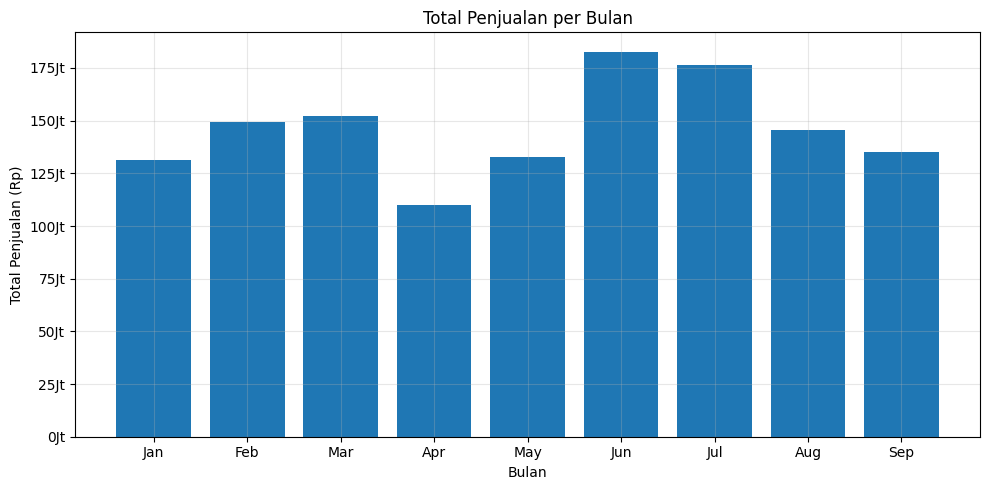

,Month,MonthName,TotalAmount
0,1,Jan,131233000
1,2,Feb,149180000
2,3,Mar,152385000
3,4,Apr,110195000
4,5,May,132639000
5,6,Jun,182769000
6,7,Jul,176286000
7,8,Aug,145624000
8,9,Sep,134965000


In [11]:
monthly_sales = df.groupby(['Month','MonthName'])['TotalAmount'].sum().reset_index().sort_values('Month')

fig, ax = plt.subplots()
ax.bar(monthly_sales['MonthName'], monthly_sales['TotalAmount'])
ax.set_title('Total Penjualan per Bulan')
ax.set_xlabel('Bulan')
ax.set_ylabel('Total Penjualan (Rp)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.0f}Jt'))
plt.tight_layout()
plt.show()

monthly_sales


## 4. Perbandingan Antar Outlet

In [12]:
outlet_summary = df.groupby('Outlet').agg(
    Jumlah_Transaksi=('ReceiptNumber','count'),
    Total_Penjualan=('TotalAmount','sum'),
    Rata_rata_Transaksi=('TotalAmount','mean'),
).round(0)
outlet_summary['Persentase_Transaksi'] = (outlet_summary['Jumlah_Transaksi'] / outlet_summary['Jumlah_Transaksi'].sum() * 100).round(1)
outlet_summary.sort_values('Total_Penjualan', ascending=False)


,Jumlah_Transaksi,Total_Penjualan,Rata_rata_Transaksi,Persentase_Transaksi
Outlet,,,,
SHOP001,26250,644108000,24537.0,48.8
SHOP003,16753,409504000,24444.0,31.1
SHOP002,10817,261664000,24190.0,20.1


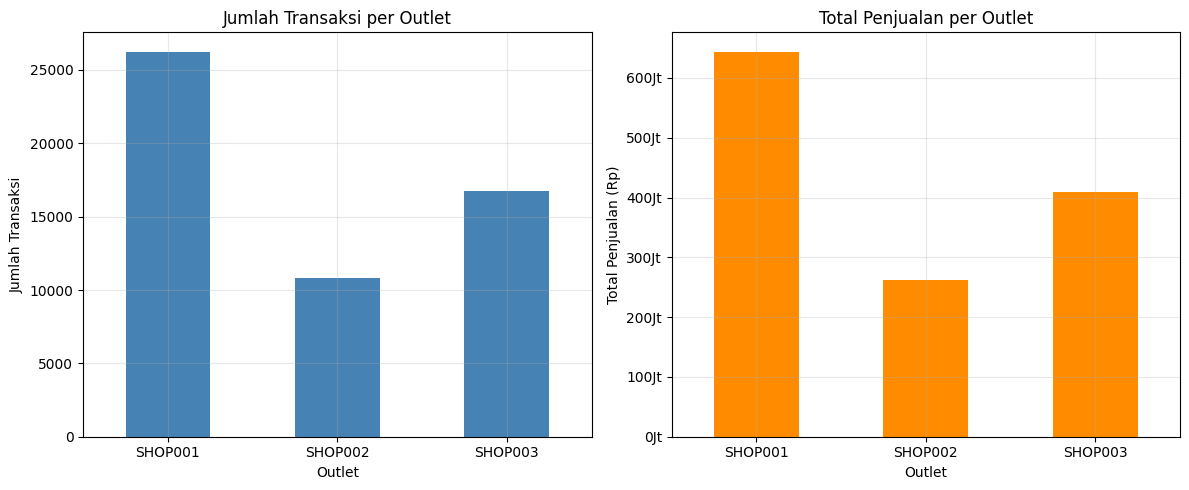

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

outlet_summary['Jumlah_Transaksi'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Jumlah Transaksi per Outlet')
axes[0].set_ylabel('Jumlah Transaksi')
axes[0].tick_params(axis='x', rotation=0)

outlet_summary['Total_Penjualan'].plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('Total Penjualan per Outlet')
axes[1].set_ylabel('Total Penjualan (Rp)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.0f}Jt'))
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


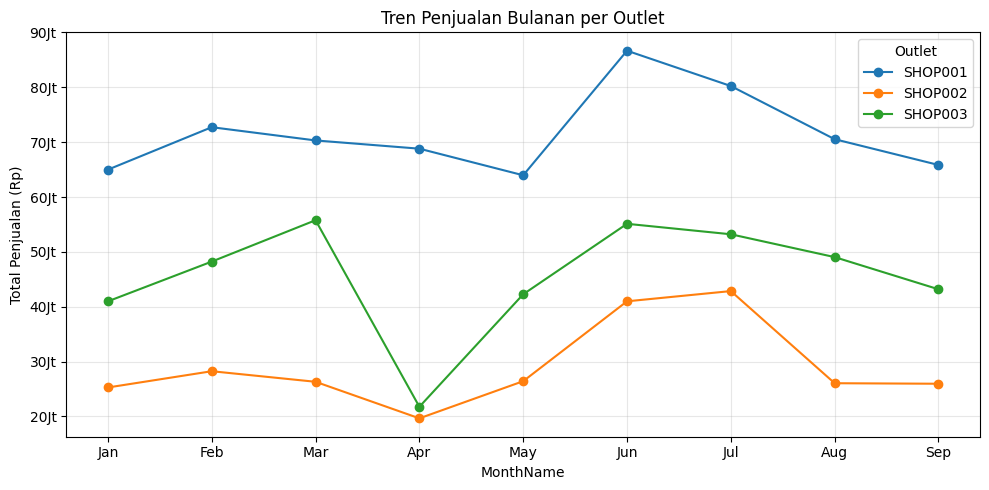

In [14]:
outlet_monthly = df.groupby(['MonthName','Month','Outlet'])['TotalAmount'].sum().reset_index().sort_values('Month')
pivot = outlet_monthly.pivot(index='MonthName', columns='Outlet', values='TotalAmount').loc[monthly_sales['MonthName']]

fig, ax = plt.subplots()
pivot.plot(ax=ax, marker='o')
ax.set_title('Tren Penjualan Bulanan per Outlet')
ax.set_ylabel('Total Penjualan (Rp)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.0f}Jt'))
plt.tight_layout()
plt.show()


## 5. Analisis Metode Pembayaran

In [15]:
payment_summary = df.groupby('PaymentMethod').agg(
    Jumlah_Transaksi=('ReceiptNumber','count'),
    Total_Penjualan=('TotalAmount','sum'),
).sort_values('Jumlah_Transaksi', ascending=False)
payment_summary['Persentase'] = (payment_summary['Jumlah_Transaksi'] / payment_summary['Jumlah_Transaksi'].sum() * 100).round(1)
payment_summary


,Jumlah_Transaksi,Total_Penjualan,Persentase
PaymentMethod,,,
BCA,42805,1081473000,79.5
Cash,10913,231061000,20.3
GoFood,102,2742000,0.2


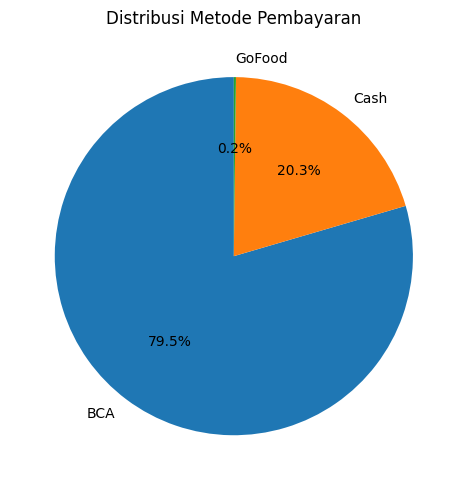

In [16]:
fig, ax = plt.subplots()
ax.pie(payment_summary['Jumlah_Transaksi'], labels=payment_summary.index, autopct='%1.1f%%', startangle=90)
ax.set_title('Distribusi Metode Pembayaran')
plt.tight_layout()
plt.show()


## 6. Analisis Penggunaan Kartu Loyalitas

In [17]:
loyalty_summary = df.groupby('UseLoyaltyCard').agg(
    Jumlah_Transaksi=('ReceiptNumber','count'),
    Rata_rata_TotalAmount=('TotalAmount','mean'),
    Transaksi_Nilai_Nol=('TotalAmount', lambda x: (x==0).sum()),
)
loyalty_summary.index = loyalty_summary.index.map({0:'Tidak Pakai', 1:'Pakai Loyalty Card'})
loyalty_summary


,Jumlah_Transaksi,Rata_rata_TotalAmount,Transaksi_Nilai_Nol
UseLoyaltyCard,,,
Tidak Pakai,52087,25251.521493,0
Pakai Loyalty Card,1733,0.000000,1733


In [18]:
# Konfirmasi dugaan: apakah semua transaksi loyalty card bernilai 0 (redeem gratis)?
loyalty_tx = df[df['UseLoyaltyCard']==1]
pct_zero = (loyalty_tx['TotalAmount']==0).mean()*100
print(f"Dari {len(loyalty_tx)} transaksi memakai loyalty card, {pct_zero:.1f}% bernilai Rp 0 (kemungkinan penukaran poin/reward gratis).")

Dari 1733 transaksi memakai loyalty card, 100.0% bernilai Rp 0 (kemungkinan penukaran poin/reward gratis).


## 7. Pola Waktu Transaksi (Jam & Hari)

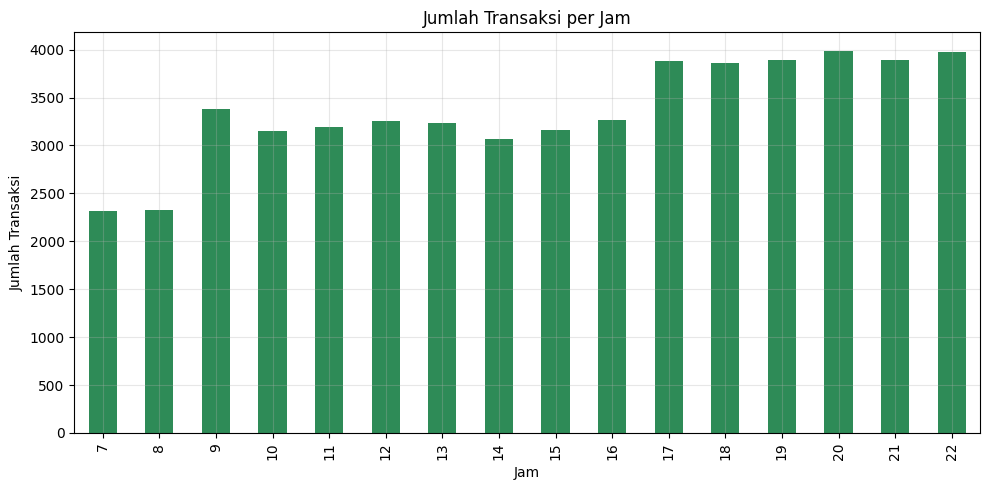

In [19]:
hourly = df.groupby('Hour').size()

fig, ax = plt.subplots()
hourly.plot(kind='bar', ax=ax, color='seagreen')
ax.set_title('Jumlah Transaksi per Jam')
ax.set_xlabel('Jam')
ax.set_ylabel('Jumlah Transaksi')
plt.tight_layout()
plt.show()


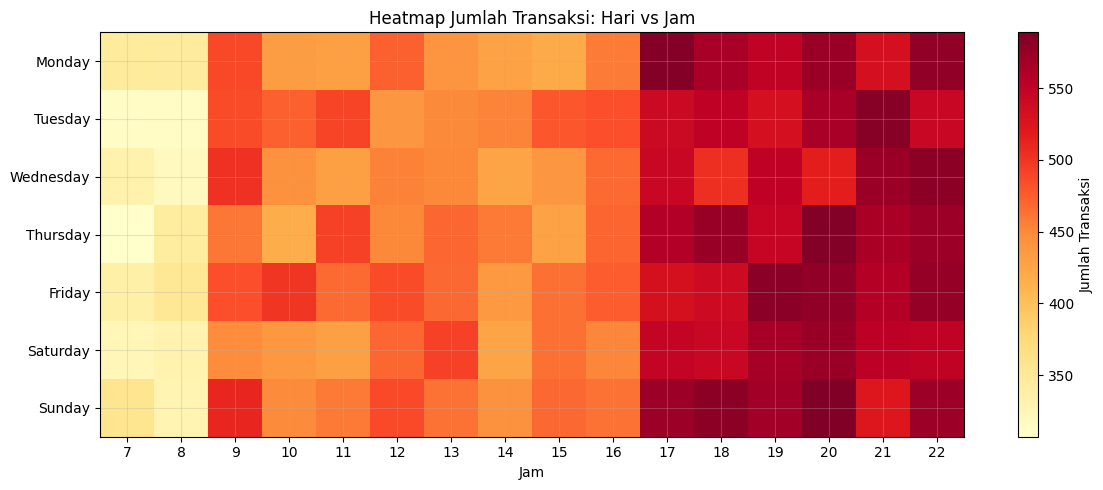

In [20]:
order_days = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
heat_data = df.pivot_table(index='DayOfWeek', columns='Hour', values='ReceiptNumber', aggfunc='count', fill_value=0)
heat_data = heat_data.reindex(order_days)

fig, ax = plt.subplots(figsize=(12,5))
im = ax.imshow(heat_data, aspect='auto', cmap='YlOrRd')
ax.set_yticks(range(len(heat_data.index)))
ax.set_yticklabels(heat_data.index)
ax.set_xticks(range(len(heat_data.columns)))
ax.set_xticklabels(heat_data.columns)
ax.set_xlabel('Jam')
ax.set_title('Heatmap Jumlah Transaksi: Hari vs Jam')
fig.colorbar(im, ax=ax, label='Jumlah Transaksi')
plt.tight_layout()
plt.show()


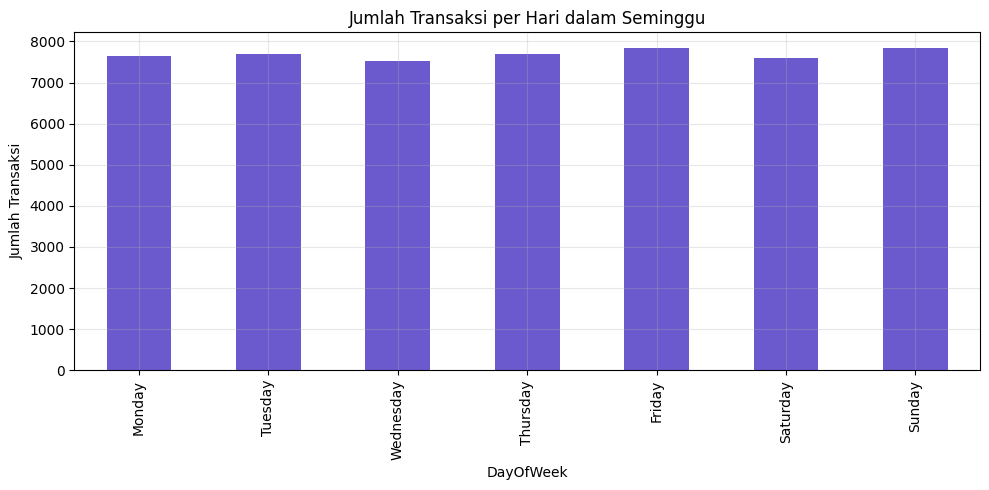

In [21]:
dow_summary = df.groupby('DayOfWeek')['ReceiptNumber'].count().reindex(order_days)

fig, ax = plt.subplots()
dow_summary.plot(kind='bar', ax=ax, color='slateblue')
ax.set_title('Jumlah Transaksi per Hari dalam Seminggu')
ax.set_ylabel('Jumlah Transaksi')
plt.tight_layout()
plt.show()


## 8. Ukuran Keranjang Belanja (Jumlah Item per Transaksi)

count    53820.000000
mean         1.151486
std          0.358526
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          2.000000
Name: TotalItem, dtype: float64


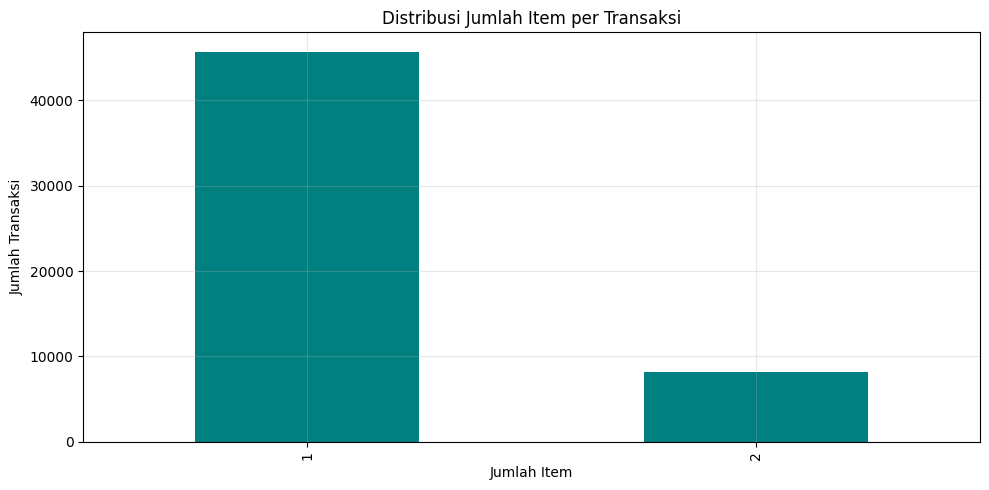

In [22]:
print(df['TotalItem'].describe())

fig, ax = plt.subplots()
df['TotalItem'].value_counts().sort_index().plot(kind='bar', ax=ax, color='teal')
ax.set_title('Distribusi Jumlah Item per Transaksi')
ax.set_xlabel('Jumlah Item')
ax.set_ylabel('Jumlah Transaksi')
plt.tight_layout()
plt.show()


## 9. Item Terlaris

Kolom `Items` berisi beberapa nama produk yang dipisahkan koma dalam satu transaksi. Kolom ini di-*explode* agar setiap baris mewakili satu item yang terjual.


In [23]:
items_series = df['Items'].str.split(',\s*').explode().str.strip()
print(f"Total item terjual (baris setelah explode): {len(items_series):,}")
print(f"Jumlah produk unik: {items_series.nunique()}")


Total item terjual (baris setelah explode): 61,973
Jumlah produk unik: 94


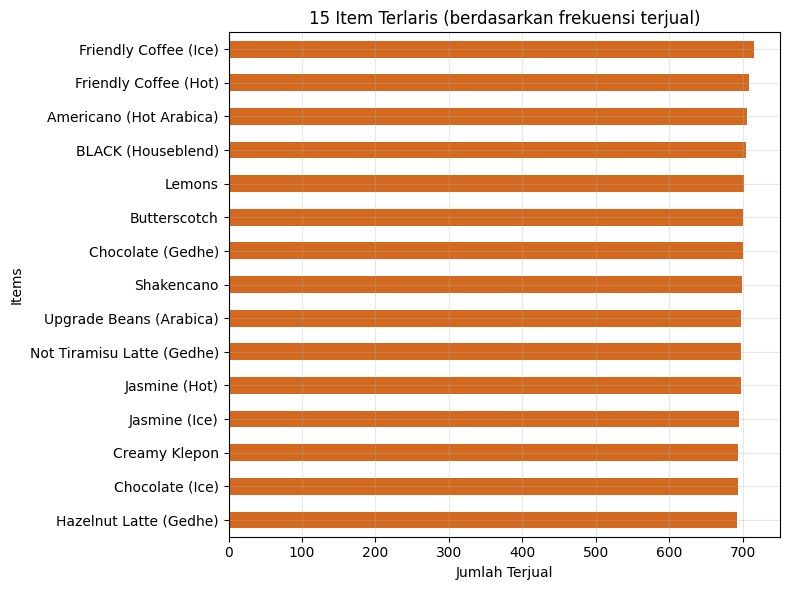

Items
Friendly Coffee (Ice)         715
Friendly Coffee (Hot)         708
Americano (Hot Arabica)       706
BLACK (Houseblend)            704
Lemons                        702
Butterscotch                  701
Chocolate (Gedhe)             700
Shakencano                    699
Upgrade Beans (Arabica)       698
Not Tiramisu Latte (Gedhe)    698
Jasmine (Hot)                 697
Jasmine (Ice)                 695
Creamy Klepon                 694
Chocolate (Ice)               693
Hazelnut Latte (Gedhe)        692
Name: count, dtype: int64

In [24]:
top_items = items_series.value_counts().head(15)

fig, ax = plt.subplots(figsize=(8,6))
top_items.sort_values().plot(kind='barh', ax=ax, color='chocolate')
ax.set_title('15 Item Terlaris (berdasarkan frekuensi terjual)')
ax.set_xlabel('Jumlah Terjual')
plt.tight_layout()
plt.show()

top_items


## 10. Ringkasan Temuan Awal

- Dataset mencakup **53.820 transaksi** dari **3 outlet** selama **9 bulan (Jan–Sep 2025)**, tanpa nilai yang hilang (*missing values*).
- **SHOP001** adalah outlet dengan transaksi dan pendapatan terbanyak, diikuti SHOP003 lalu SHOP002.
- Mayoritas pembayaran dilakukan via **BCA**, jauh melebihi Cash dan GoFood.
- Transaksi dengan `TotalAmount = 0` (±3,2% dari seluruh data) hampir seluruhnya terkait dengan **penggunaan kartu loyalitas**, mengindikasikan penukaran reward/item gratis.
- Terdapat pola jam sibuk yang terlihat jelas pada heatmap jam vs hari — berguna untuk perencanaan jadwal staf dan stok.
- Sebagian besar transaksi hanya berisi **1 item**, menunjukkan peluang strategi *upselling/bundling* untuk menaikkan rata-rata nilai transaksi.
- Item-item tertentu mendominasi penjualan — bisa dijadikan fokus promosi atau dipastikan ketersediaan stoknya.

> Notebook ini adalah eksplorasi awal (EDA). Analisis lanjutan (misalnya market basket analysis, forecasting penjualan, atau segmentasi pelanggan) bisa dikembangkan dari sini.
